<a href="https://colab.research.google.com/github/a01770768-oss/JobishViri/blob/main/A9_Viridiana_Hurtado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from statsmodels.stats.stattools import durbin_watson
from google.colab import files

In [2]:
uploaded = files.upload()

df = pd.read_csv("antropometria-dataset-1.csv")

df.head()

Saving antropometria-dataset-1.csv to antropometria-dataset-1.csv


,folio,intp,entidad,desc_ent,sexo,edad,meses,peso,ropa,talla,...,hpresion,tbrazo,htension,PrimaryLast,code_upm,est_dis,est_urb,est_marg,pondef,est_var
0,210295,2,21,PUEBLA,2,38,8,73.70,2,146.4,...,16:30,2,16:35,1,R2101,5,3,1,3470.002176,215
1,101655,3,10,DURANGO,2,11,11,35.65,2,145.1,...,15:25,3,15:25,1,M1041,1,1,1,417.946672,101
2,10287,6,1,AGUASCALIENTES,2,18,8,54.80,1,162.0,...,9:40,1,9:40,1,M0108,5,3,1,472.980811,15
3,91526,4,9,DISTRITO FEDERAL,1,10,8,33.40,2,146.5,...,7:40,3,7:45,1,M0931,4,3,2,1832.581391,94
4,210939,3,21,PUEBLA,2,19,3,97.95,2,161.0,...,6:00,2,6:00,1,M2123,5,3,1,7622.066564,215


In [3]:
df.columns

Index(['folio', 'intp', 'entidad', 'desc_ent', 'sexo', 'edad', 'meses', 'peso',
       'ropa', 'talla', 'emb', 'temb', 'cintura', 'cadera', 'sistol',
       'diastol', 'hpresion', 'tbrazo', 'htension', 'PrimaryLast', 'code_upm',
       'est_dis', 'est_urb', 'est_marg', 'pondef', 'est_var'],
      dtype='object')

In [4]:
analysis = df[["peso", "cintura"]].dropna().copy()

analysis.head()

,peso,cintura
0,73.70,98.7
1,35.65,64.0
2,54.80,67.6
3,33.40,60.6
4,97.95,113.0


In [5]:
model = smf.ols("peso ~ cintura", data=analysis).fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   peso   R-squared:                       0.627
Model:                            OLS   Adj. R-squared:                  0.627
Method:                 Least Squares   F-statistic:                 3.028e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        05:23:36   Log-Likelihood:                -68622.
No. Observations:               18032   AIC:                         1.372e+05
Df Residuals:                   18030   BIC:                         1.373e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -8.3137      0.427    -19.458      0.000      -9.151      -7.476
cintura        0.8316      0.005    173.999      0.000       0.822       0.841
==============================================================================
Omnibus:                    12737.948   Durbin-Watson:                   1.884
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          1022852.813
Skew:                          -2.683   Prob(JB):                         0.00
Kurtosis:                      39.505   Cond. No.                         472.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [6]:
b0 = model.params["Intercept"]
b1 = model.params["cintura"]

print("b0 =", b0)
print("b1 =", b1)
print()
print("Modelo estimado:")
print("peso =", b0, "+", b1, "* cintura")

b0 = -8.313656308821756
b1 = 0.8315676239469251

Modelo estimado:
peso = -8.313656308821756 + 0.8315676239469251 * cintura


In [7]:
analysis["peso_estimado"] = model.fittedvalues

analysis.head()

,peso,cintura,peso_estimado
0,73.70,98.7,73.762068
1,35.65,64.0,44.906672
2,54.80,67.6,47.900315
3,33.40,60.6,42.079342
4,97.95,113.0,85.653485


In [8]:
analysis["residuales"] = model.resid

analysis.head()

,peso,cintura,peso_estimado,residuales
0,73.70,98.7,73.762068,-0.062068
1,35.65,64.0,44.906672,-9.256672
2,54.80,67.6,47.900315,6.899685
3,33.40,60.6,42.079342,-8.679342
4,97.95,113.0,85.653485,12.296515


In [9]:
analysis["residual_manual"] = analysis["peso"] - analysis["peso_estimado"]

analysis.head()

,peso,cintura,peso_estimado,residuales,residual_manual
0,73.70,98.7,73.762068,-0.062068,-0.062068
1,35.65,64.0,44.906672,-9.256672,-9.256672
2,54.80,67.6,47.900315,6.899685,6.899685
3,33.40,60.6,42.079342,-8.679342,-8.679342
4,97.95,113.0,85.653485,12.296515,12.296515


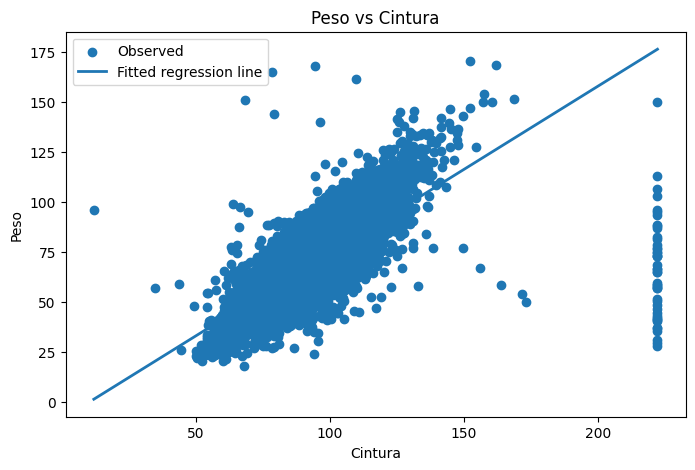

In [10]:
plt.figure(figsize=(8,5))

plt.scatter(
    analysis["cintura"],
    analysis["peso"],
    label="Observed"
)

order = np.argsort(analysis["cintura"].to_numpy())

plt.plot(
    analysis["cintura"].to_numpy()[order],
    analysis["peso_estimado"].to_numpy()[order],
    linewidth=2,
    label="Fitted regression line"
)

plt.xlabel("Cintura")
plt.ylabel("Peso")
plt.title("Peso vs Cintura")
plt.legend()

plt.show()

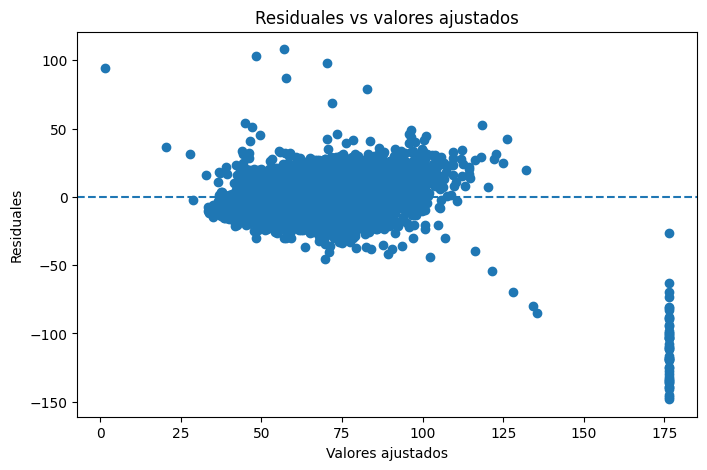

In [11]:
plt.figure(figsize=(8,5))

plt.scatter(
    model.fittedvalues,
    model.resid
)

plt.axhline(0, linestyle="--")

plt.xlabel("Valores ajustados")
plt.ylabel("Residuales")
plt.title("Residuales vs valores ajustados")

plt.show()

In [12]:
hombres = df[df["sexo"] == 1].copy()
mujeres = df[df["sexo"] == 2].copy()

print("Hombres:", len(hombres))
print("Mujeres:", len(mujeres))

Hombres: 8154
Mujeres: 10486


In [13]:
hombres_analysis = hombres[["peso", "cintura"]].dropna().copy()

model_hombres = smf.ols(
    "peso ~ cintura",
    data=hombres_analysis
).fit()

model_hombres.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   peso   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                 2.022e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        05:23:56   Log-Likelihood:                -30486.
No. Observations:                8154   AIC:                         6.098e+04
Df Residuals:                    8152   BIC:                         6.099e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -16.5015      0.599    -27.556      0.000     -17.675     -15.328
cintura        0.9558      0.007    142.200      0.000       0.943       0.969
==============================================================================
Omnibus:                     6572.799   Durbin-Watson:                   1.889
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           878711.348
Skew:                          -3.142   Prob(JB):                         0.00
Kurtosis:                      53.466   Cond. No.                         474.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [14]:
b0_h = model_hombres.params["Intercept"]
b1_h = model_hombres.params["cintura"]

print("b0 hombres =", b0_h)
print("b1 hombres =", b1_h)

b0 hombres = -16.501454915572378
b1 hombres = 0.9557736731097393


In [15]:
hombres_analysis["peso_estimado"] = model_hombres.fittedvalues
hombres_analysis["residuales"] = model_hombres.resid

hombres_analysis.head()

,peso,cintura,peso_estimado,residuales
3,33.400,60.60,41.418430,-8.018430
5,31.900,59.50,40.367079,-8.467079
9,48.025,79.65,59.625918,-11.600918
17,31.500,60.70,41.514007,-10.014007
21,59.850,96.20,75.443972,-15.593972


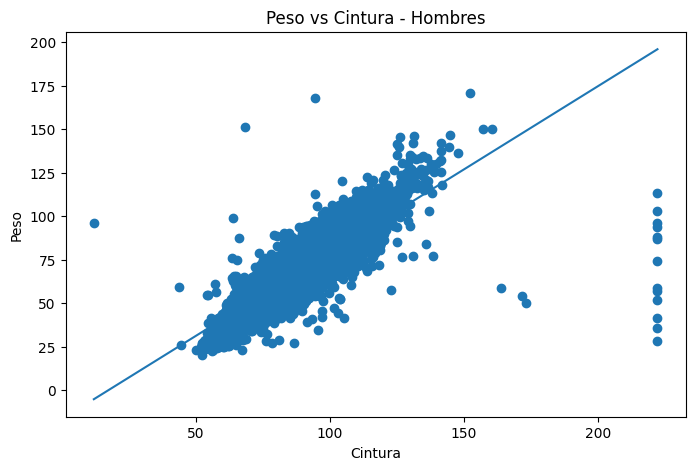

In [16]:
plt.figure(figsize=(8,5))

plt.scatter(
    hombres_analysis["cintura"],
    hombres_analysis["peso"]
)

order = np.argsort(hombres_analysis["cintura"].to_numpy())

plt.plot(
    hombres_analysis["cintura"].to_numpy()[order],
    hombres_analysis["peso_estimado"].to_numpy()[order]
)

plt.xlabel("Cintura")
plt.ylabel("Peso")
plt.title("Peso vs Cintura - Hombres")

plt.show()

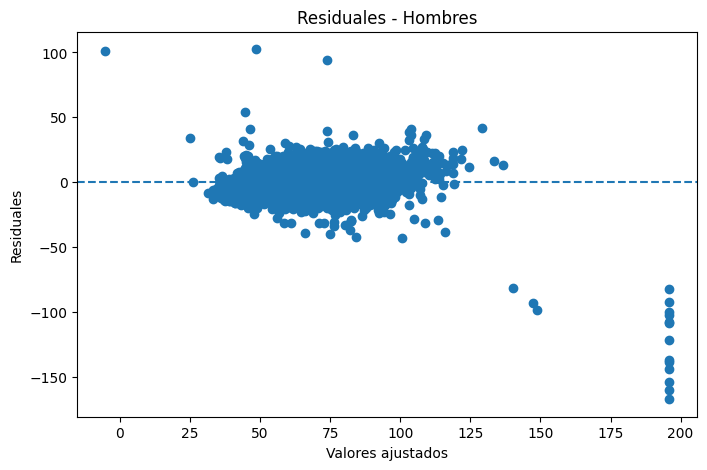

In [17]:
plt.figure(figsize=(8,5))

plt.scatter(
    model_hombres.fittedvalues,
    model_hombres.resid
)

plt.axhline(0, linestyle="--")

plt.xlabel("Valores ajustados")
plt.ylabel("Residuales")
plt.title("Residuales - Hombres")

plt.show()

In [18]:
mujeres_analysis = mujeres[["peso", "cintura"]].dropna().copy()

model_mujeres = smf.ols(
    "peso ~ cintura",
    data=mujeres_analysis
).fit()

model_mujeres.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   peso   R-squared:                       0.583
Model:                            OLS   Adj. R-squared:                  0.583
Method:                 Least Squares   F-statistic:                 1.381e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        05:24:10   Log-Likelihood:                -37386.
No. Observations:                9878   AIC:                         7.478e+04
Df Residuals:                    9876   BIC:                         7.479e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.1852      0.562     -3.887      0.000      -3.287      -1.083
cintura        0.7368      0.006    117.510      0.000       0.724       0.749
==============================================================================
Omnibus:                     6504.425   Durbin-Watson:                   1.913
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           441820.169
Skew:                          -2.437   Prob(JB):                         0.00
Kurtosis:                      35.399   Cond. No.                         470.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [19]:
b0_m = model_mujeres.params["Intercept"]
b1_m = model_mujeres.params["cintura"]

print("b0 mujeres =", b0_m)
print("b1 mujeres =", b1_m)

b0 mujeres = -2.18515708917074
b1 mujeres = 0.7367878416907191


In [20]:
mujeres_analysis["peso_estimado"] = model_mujeres.fittedvalues
mujeres_analysis["residuales"] = model_mujeres.resid

mujeres_analysis.head()

,peso,cintura,peso_estimado,residuales
0,73.70,98.7,70.535803,3.164197
1,35.65,64.0,44.969265,-9.319265
2,54.80,67.6,47.621701,7.178299
4,97.95,113.0,81.071869,16.878131
6,31.95,57.3,40.032786,-8.082786


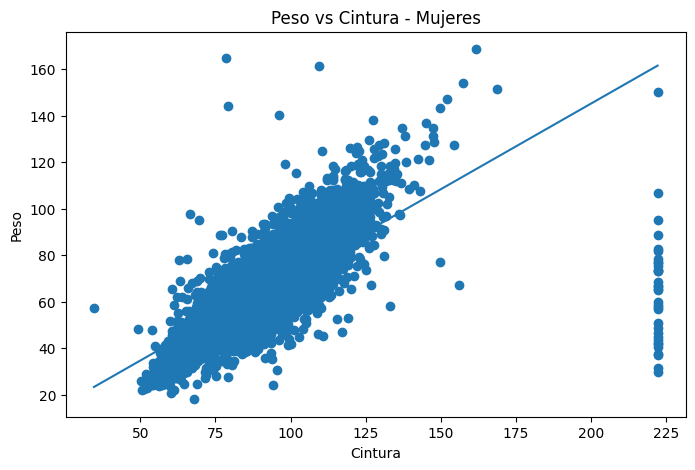

In [21]:
plt.figure(figsize=(8,5))

plt.scatter(
    mujeres_analysis["cintura"],
    mujeres_analysis["peso"]
)

order = np.argsort(mujeres_analysis["cintura"].to_numpy())

plt.plot(
    mujeres_analysis["cintura"].to_numpy()[order],
    mujeres_analysis["peso_estimado"].to_numpy()[order]
)

plt.xlabel("Cintura")
plt.ylabel("Peso")
plt.title("Peso vs Cintura - Mujeres")

plt.show()

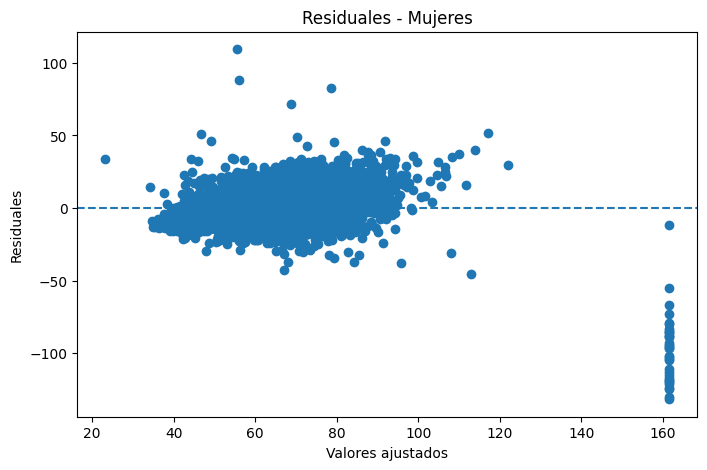

In [22]:
plt.figure(figsize=(8,5))

plt.scatter(
    model_mujeres.fittedvalues,
    model_mujeres.resid
)

plt.axhline(0, linestyle="--")

plt.xlabel("Valores ajustados")
plt.ylabel("Residuales")
plt.title("Residuales - Mujeres")

plt.show()

In [23]:
model_cadera = smf.ols(
    "cadera ~ peso",
    data=df
).fit()

print("R-squared =", model_cadera.rsquared)

R-squared = 0.6038232783357169


In [24]:
correlacion = df["peso"].corr(df["cintura"])

print("Correlación =", correlacion)

Correlación = 0.79167686976069


In [25]:
model_presion = smf.ols(
    "diastol ~ sistol",
    data=df
).fit()

model_presion.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                diastol   R-squared:                       0.441
Model:                            OLS   Adj. R-squared:                  0.441
Method:                 Least Squares   F-statistic:                 1.469e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        05:24:24   Log-Likelihood:                -66351.
No. Observations:               18640   AIC:                         1.327e+05
Df Residuals:                   18638   BIC:                         1.327e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     23.6843      0.432     54.811      0.000      22.837      24.531
sistol         0.4375      0.004    121.220      0.000       0.430       0.445
==============================================================================
Omnibus:                     1040.446   Durbin-Watson:                   1.746
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4079.429
Skew:                           0.118   Prob(JB):                         0.00
Kurtosis:                       5.280   Cond. No.                         830.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [26]:
dw = durbin_watson(model_presion.resid)

print("Durbin-Watson =", dw)

Durbin-Watson = 1.7463985152850534


In [27]:
model_multiple = smf.ols(
    "diastol ~ sistol + edad + peso + cintura",
    data=df
).fit()

model_multiple.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                diastol   R-squared:                       0.458
Model:                            OLS   Adj. R-squared:                  0.458
Method:                 Least Squares   F-statistic:                     3812.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        05:24:28   Log-Likelihood:                -63952.
No. Observations:               18032   AIC:                         1.279e+05
Df Residuals:                   18027   BIC:                         1.280e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     20.3297      0.520     39.089      0.000      19.310      21.349
sistol         0.4140      0.004     94.447      0.000       0.405       0.423
edad          -0.0272      0.004     -6.934      0.000      -0.035      -0.020
peso           0.0825      0.006     14.154      0.000       0.071       0.094
cintura        0.0202      0.007      3.072      0.002       0.007       0.033
==============================================================================
Omnibus:                     1031.138   Durbin-Watson:                   1.769
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3722.633
Skew:                           0.189   Prob(JB):                         0.00
Kurtosis:                       5.194   Cond. No.                     1.39e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.39e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [28]:
print(model_multiple.params)

Intercept    20.329676
sistol        0.414001
edad         -0.027194
peso          0.082546
cintura       0.020167
dtype: float64


In [29]:
b0_multiple = model_multiple.params["Intercept"]

print("b0 =", b0_multiple)

b0 = 20.32967638696536


In [30]:
residuos_multiple = model_multiple.resid

residuos_multiple.head()

,0
0,-0.305991
1,-3.244064
2,-13.914068
3,10.569038
4,-6.485321


In [31]:
mediana_residuos = residuos_multiple.median()

print("Mediana de los residuales =", mediana_residuos)

Mediana de los residuales = -0.0021017816189328187


In [32]:
df_model = df[
    ["diastol", "sistol", "edad", "peso", "cintura"]
].dropna().copy()

model_multiple_2 = smf.ols(
    "diastol ~ sistol + edad + peso + cintura",
    data=df_model
).fit()

df_model["diastol_estimado"] = model_multiple_2.fittedvalues
df_model["residuales"] = model_multiple_2.resid

df_model.head()

,diastol,sistol,edad,peso,cintura,diastol_estimado,residuales
0,53.25,63.25,38,73.70,98.7,53.555991,-0.305991
1,50.00,70.00,11,35.65,64.0,53.244064,-3.244064
2,41.00,70.50,18,54.80,67.6,54.914068,-13.914068
3,64.00,71.00,10,33.40,60.6,53.430962,10.569038
4,53.50,72.00,19,97.95,113.0,59.985321,-6.485321


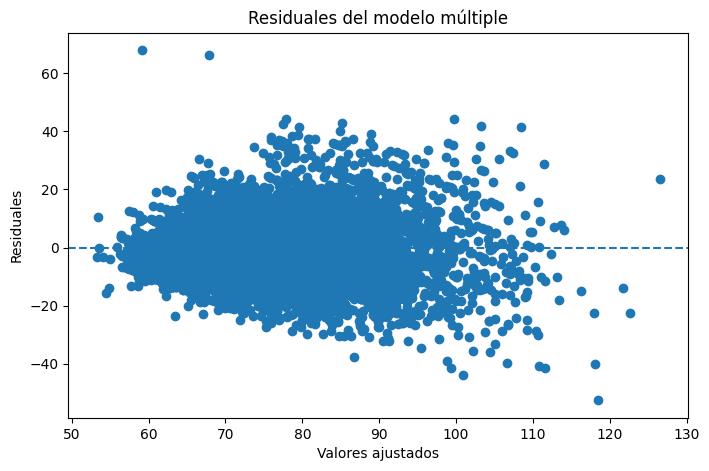

In [33]:
plt.figure(figsize=(8,5))

plt.scatter(
    model_multiple_2.fittedvalues,
    model_multiple_2.resid
)

plt.axhline(0, linestyle="--")

plt.xlabel("Valores ajustados")
plt.ylabel("Residuales")
plt.title("Residuales del modelo múltiple")

plt.show()

# Conclusions

A simple linear regression model was used to analyze the relationship between weight and waist circumference. The results show a positive relationship, which means that people with larger waist circumference tend to have higher weight.

The analysis was repeated separately for men and women. In both groups, the relationship between weight and waist circumference remained positive, although the regression coefficients were not exactly the same.

The residuals represent the difference between the observed values and the values estimated by the regression model. Their analysis helps evaluate how well the model fits the data.
